### Pillow 3: Bearbeiten - Übungen

In diesem Notebook bearbeitest du Fotos mit fertigen Werkzeugen von Pillow: ausschneiden, verkleinern, drehen, spiegeln, Farbkanäle trennen,
Filter anwenden, Helligkeit und Kontrast ändern, Bilder übereinanderlegen und animierte GIFs erzeugen, also das, was ein Bildbearbeitungsprogramm kann,
nur mit Code (und deshalb auch für hundert Bilder auf einmal).

Die Reihe hat vier Notebooks:

1. Grundlagen: Bilder erzeugen, Pixel, Farben, Speichern und Öffnen
2. Zeichnen: Formen, Text, Grafiken mit Schleifen und Funktionen
3. **Bearbeiten**: Ausschneiden, Drehen, Filter, Helligkeit, Collagen, animierte GIFs (dieses Notebook)
4. Pixel: Bildverarbeitung selbst programmieren, mit Schleifen und mit numpy

Vorausgesetzt werden *Pillow: Grundlagen* und *Pillow: Zeichnen*.

**Bilder anzeigen:** Steht ein Bild in der **letzten Zeile** einer Zelle, zeigt JupyterLab es an. Mehrere Bilder in einer Zelle zeigt man mit `display(bild)` an.
Die erwarteten Ausgaben zeigen die Bilder höchstens 320 Pixel groß; große Bilder (Fotos) sind dort verkleinert.

**Fotos:** Neben den Notebooks liegen zwei Fotos mit je 640 × 427 Pixeln: `pagode.png` (ein chinesischer Tempel) und `bluete.png` (eine Blüte).
Fotos: Daniel Buechele, [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/), aus dem Paket scikit-learn.
Eigene Fotos kannst du mit dem Pfeil-Symbol über der Dateiliste links hochladen und dann mit `Image.open('dateiname.jpg')` öffnen.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ überlegst du zuerst, führst dann die Zelle aus und vergleichst.
Die aufklappbare Lösung erklärt dort, wie die Ausgabe zustande kommt.

#### Bildanzeige einrichten

**Führe diese Zelle zuerst aus** (nach jedem Neustart des Kernels wieder). Im Browser-Python von JupyterLite zeigt `display(bild)` sonst nur ein leeres Bild an;
die Zelle sorgt dafür, dass Pillow-Bilder dort richtig übertragen werden. Wie sie funktioniert, musst du nicht verstehen.

In [ ]:
import base64
import io
from IPython import get_ipython
from PIL import Image

def als_png(bild):
    puffer = io.BytesIO()
    bild.save(puffer, 'PNG')
    return base64.b64encode(puffer.getvalue()).decode('ascii')

def kein_jpeg(bild):
    return None

ipython = get_ipython()
if ipython is not None:
    ipython.display_formatter.formatters['image/png'].for_type(Image.Image, als_png)
    ipython.display_formatter.formatters['image/jpeg'].for_type(Image.Image, kein_jpeg)
print('Bereit: Bilder werden auch mit display() angezeigt.')

## 1. Ausschneiden und Größe ändern

#### `crop()` und `resize()`

- `foto.crop((links, oben, rechts, unten))` schneidet ein Rechteck aus. `rechts` und `unten` gehören **nicht** mehr dazu, das Ergebnis ist also
  `rechts - links` Pixel breit.
- `foto.resize((breite, hoehe))` ändert die Größe. Passt das Verhältnis von Breite zu Höhe nicht, wird das Bild verzerrt.

Beide geben ein **neues** Bild zurück; `foto` bleibt unverändert.

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')

ausschnitt = foto.crop((200, 50, 400, 250))
print(ausschnitt.size)
display(ausschnitt)
klein = foto.resize((160, 107))
print(klein.size)
klein

#### Seitenverhältnis erhalten: `thumbnail()`

`foto.thumbnail((200, 200))` verkleinert das Bild so, dass es in ein 200 × 200-Feld passt, **ohne** es zu verzerren. Achtung: `thumbnail()` verändert das Bild
selbst und gibt nichts zurück; wer das Original behalten will, macht vorher eine Kopie mit `foto.copy()`.

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')

vorschau = foto.copy()
vorschau.thumbnail((200, 200))
print(foto.size, vorschau.size)
vorschau

#### Aufgabe 1.1

Schneide aus der Pagode das linke obere Viertel aus (die halbe Breite und Höhe) und gib seine Größe aus.

**Erwartete Ausgabe:**

```
(320, 213)
```

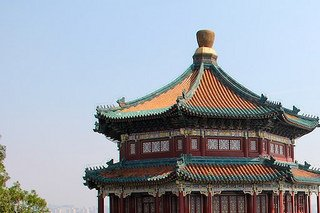

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
viertel = foto.crop((0, 0, foto.width // 2, foto.height // 2))
print(viertel.size)
viertel
```

</details>

#### Aufgabe 1.2

Schneide aus der Mitte der Blüte ein Quadrat mit 200 × 200 Pixeln aus. Berechne die Ecken aus `foto.width` und `foto.height`.

**Erwartete Ausgabe:**

```
(200, 200)
```

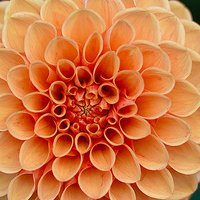

In [ ]:
from PIL import Image

foto = Image.open('bluete.png')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('bluete.png')
links = (foto.width - 200) // 2
oben = (foto.height - 200) // 2
quadrat = foto.crop((links, oben, links + 200, oben + 200))
print(quadrat.size)
quadrat
```

</details>

#### Aufgabe 1.3

Verkleinere die Pagode auf ein Viertel der Breite und Höhe (mit `resize()` und `//`) und gib die neue Größe aus.

**Erwartete Ausgabe:**

```
(160, 106)
```

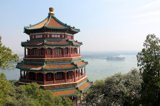

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
klein = foto.resize((foto.width // 4, foto.height // 4))
print(klein.size)
klein
```

</details>

#### Aufgabe 1.4

Verzerre die Blüte absichtlich auf 300 × 100 Pixel und daneben auf 100 × 300 Pixel (zwei `display()`).

**Erwartete Ausgabe:**



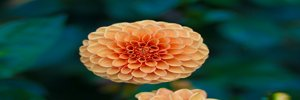

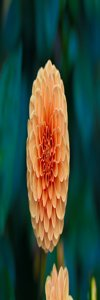

In [ ]:
from PIL import Image

foto = Image.open('bluete.png')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('bluete.png')
display(foto.resize((300, 100)))
display(foto.resize((100, 300)))
```

</details>

#### Aufgabe 1.5

Erzeuge Vorschaubilder der Pagode, die in 100 × 100, 150 × 150 und 300 × 300 passen (jeweils von einer Kopie), und gib ihre Größen aus.

**Erwartete Ausgabe:**

```
(100, 67)
(150, 100)
(300, 200)
```

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
for groesse in [100, 150, 300]:
    vorschau = foto.copy()
    vorschau.thumbnail((groesse, groesse))
    print(vorschau.size)
```

</details>

#### Aufgabe 1.6

Vergrößere einen 40 × 40-Ausschnitt der Pagode bei (300 | 150) auf 320 × 320, einmal mit `resample=Image.NEAREST` (Pixel werden zu Quadraten) und einmal mit dem
Standard (geglättet).

**Erwartete Ausgabe:**



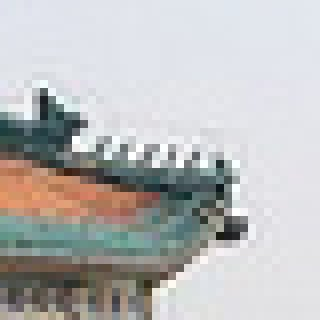

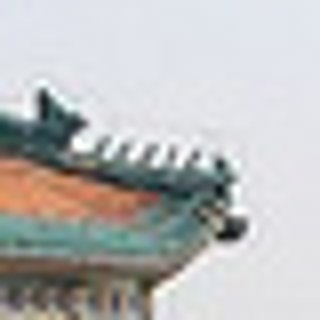

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
ausschnitt = foto.crop((300, 150, 340, 190))
display(ausschnitt.resize((320, 320), resample=Image.NEAREST))
display(ausschnitt.resize((320, 320)))
```

</details>

#### Aufgabe 1.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from PIL import Image

bild = Image.new('RGB', (800, 400))
print(bild.crop((100, 100, 300, 150)).size)
kopie = bild.copy()
kopie.thumbnail((200, 200))
print(kopie.size, bild.size)

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
(200, 50)
(200, 100) (800, 400)
```

- Der Ausschnitt ist `300 - 100 = 200` breit und `150 - 100 = 50` hoch: `(200, 50)`.
- `thumbnail()` verkleinert das Verhältnis 2 : 1 so, dass es in 200 × 200 passt: `(200, 100)`. Das Original bleibt `(800, 400)`.

</details>

## 2. Drehen, Spiegeln und Rahmen

#### `rotate()`, `transpose()` und `ImageOps`

- `foto.rotate(30)` dreht **gegen** den Uhrzeigersinn um 30°. Das Bild behält seine Größe, Ecken werden abgeschnitten und die freien Ecken schwarz.
  Mit `expand=True` wird das Bild so vergrößert, dass alles hineinpasst, mit `fillcolor='white'` werden die Ecken weiß.
- `foto.transpose(Image.Transpose.FLIP_LEFT_RIGHT)` spiegelt links/rechts, `FLIP_TOP_BOTTOM` oben/unten, `ROTATE_90` dreht um genau 90°.
- Das Modul `ImageOps` hat viele fertige Funktionen: `ImageOps.mirror(foto)`, `ImageOps.flip(foto)`, `ImageOps.grayscale(foto)`, `ImageOps.invert(foto)` (Negativ)
  und `ImageOps.expand(foto, border=10, fill='white')` (Rahmen).

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageOps

klein = foto.resize((213, 142))
display(klein.rotate(30))
display(klein.rotate(30, expand=True, fillcolor='white'))
display(ImageOps.mirror(klein))
ImageOps.expand(klein, border=10, fill='black')

#### Aufgabe 2.1

Drehe die verkleinerte Pagode um genau 90° mit `transpose()` und gib die Größe vorher und nachher aus.

**Erwartete Ausgabe:**

```
(213, 142) (142, 213)
```

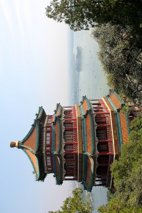

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageOps

klein = foto.resize((213, 142))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageOps

klein = foto.resize((213, 142))
gedreht = klein.transpose(Image.Transpose.ROTATE_90)
print(klein.size, gedreht.size)
gedreht
```

</details>

#### Aufgabe 2.2

Zeige die verkleinerte Pagode auf den Kopf gestellt (oben/unten gespiegelt) und als Negativ an.

**Erwartete Ausgabe:**



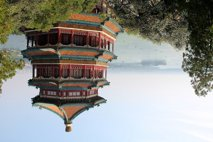

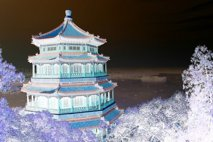

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageOps

klein = foto.resize((213, 142))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageOps

klein = foto.resize((213, 142))
display(ImageOps.flip(klein))
display(ImageOps.invert(klein))
```

</details>

#### Aufgabe 2.3

Drehe die verkleinerte Pagode um 45° mit `expand=True` und weißen Ecken und gib die neue Größe aus. Sie ist größer als das Original.

**Erwartete Ausgabe:**

```
(253, 252)
```

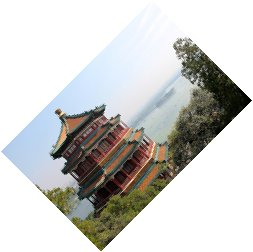

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageOps

klein = foto.resize((213, 142))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageOps

klein = foto.resize((213, 142))
gedreht = klein.rotate(45, expand=True, fillcolor='white')
print(gedreht.size)
gedreht
```

</details>

#### Aufgabe 2.4

Gib dem verkleinerten Foto einen doppelten Rahmen: erst 5 Pixel weiß, dann 15 Pixel dunkelgrau (`'#333333'`). Gib die Größe vorher und nachher aus.

**Erwartete Ausgabe:**

```
(213, 142) (253, 182)
```

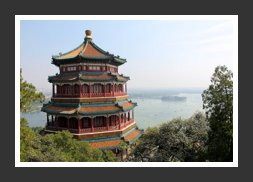

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageOps

klein = foto.resize((213, 142))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageOps

klein = foto.resize((213, 142))
gerahmt = ImageOps.expand(ImageOps.expand(klein, border=5, fill='white'), border=15, fill='#333333')
print(klein.size, gerahmt.size)
gerahmt
```

</details>

#### Aufgabe 2.5

`ImageOps.fit(foto, (150, 150))` schneidet ein Bild so zu, dass es genau 150 × 150 groß ist (die Mitte bleibt erhalten). Erzeuge damit quadratische Vorschaubilder beider Fotos.

**Erwartete Ausgabe:**

```
pagode.png (150, 150)
bluete.png (150, 150)
```

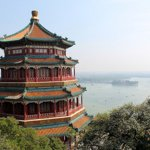

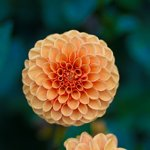

In [ ]:
from PIL import Image, ImageOps
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageOps
for name in ['pagode.png', 'bluete.png']:
    vorschau = ImageOps.fit(Image.open(name), (150, 150))
    print(name, vorschau.size)
    display(vorschau)
```

</details>

#### Aufgabe 2.6

Zeige die verkleinerte Pagode in Schritten von 60° gedreht an (0°, 60°, ..., 300°), jedes Bild mit `expand=True` und weißen Ecken, als Vorschaubild in 120 × 120.

**Erwartete Ausgabe:**



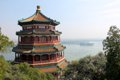

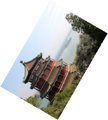

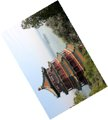

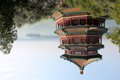

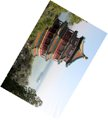

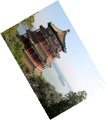

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageOps

klein = foto.resize((213, 142))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageOps

klein = foto.resize((213, 142))
for winkel in range(0, 360, 60):
    bild = klein.rotate(winkel, expand=True, fillcolor='white')
    bild.thumbnail((120, 120))
    display(bild)
```

</details>

#### Aufgabe 2.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from PIL import Image

bild = Image.new('RGB', (300, 100))
print(bild.rotate(90).size)
print(bild.rotate(90, expand=True).size)
print(bild.transpose(Image.Transpose.ROTATE_90).size)

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
(300, 100)
(100, 300)
(100, 300)
```

- Ohne `expand` behält das Bild seine Größe: `(300, 100)` (Teile werden abgeschnitten).
- Mit `expand=True` wird es so groß, dass alles hineinpasst: `(100, 300)`.
- `transpose(ROTATE_90)` vertauscht immer Breite und Höhe: `(100, 300)`.

</details>

## 3. Farbkanäle

#### `split()` und `merge()`

Ein RGB-Bild besteht aus drei **Kanälen**. `r, g, b = foto.split()` trennt sie in drei Graustufenbilder: Je heller ein Pixel im Kanal `r`, desto mehr Rot hat es.
`Image.merge('RGB', (r, g, b))` setzt Kanäle wieder zusammen, auch in anderer Reihenfolge. `foto.getchannel('R')` liefert einen einzelnen Kanal.

In [ ]:
from PIL import Image

foto = Image.open('bluete.png')

klein = foto.resize((213, 142))
r, g, b = klein.split()
display(r)
display(g)
display(b)
Image.merge('RGB', (b, g, r))

#### Aufgabe 3.1

Trenne die verkleinerte Blüte in ihre Kanäle und gib den Modus und die Größe des Rot-Kanals aus. Zeige den Grün-Kanal an.

**Erwartete Ausgabe:**

```
L (213, 142)
```

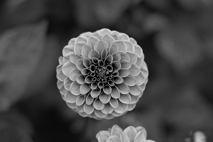

In [ ]:
from PIL import Image

foto = Image.open('bluete.png')

klein = foto.resize((213, 142))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('bluete.png')

klein = foto.resize((213, 142))
r, g, b = klein.split()
print(r.mode, r.size)
g
```

</details>

#### Aufgabe 3.2

Zeige nur den Rotanteil der Blüte **in Rot** an: Setze dazu den Rot-Kanal mit zwei schwarzen Kanälen zusammen (`Image.new('L', klein.size, 0)`).

**Erwartete Ausgabe:**



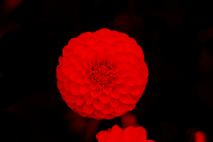

In [ ]:
from PIL import Image

foto = Image.open('bluete.png')

klein = foto.resize((213, 142))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('bluete.png')

klein = foto.resize((213, 142))
r, g, b = klein.split()
schwarz = Image.new('L', klein.size, 0)
Image.merge('RGB', (r, schwarz, schwarz))
```

</details>

#### Aufgabe 3.3

Vertausche Rot und Grün der Blüte und zeige das Ergebnis an. Gib die Farbe des Pixels (100 | 70) vorher und nachher aus.

**Erwartete Ausgabe:**

```
(204, 100, 61) (100, 204, 61)
```

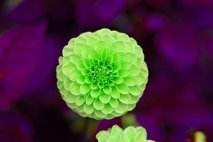

In [ ]:
from PIL import Image

foto = Image.open('bluete.png')

klein = foto.resize((213, 142))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('bluete.png')

klein = foto.resize((213, 142))
r, g, b = klein.split()
vertauscht = Image.merge('RGB', (g, r, b))
print(klein.getpixel((100, 70)), vertauscht.getpixel((100, 70)))
vertauscht
```

</details>

#### Aufgabe 3.4

Gib mit `ImageStat.Stat(foto).mean` (aus `PIL`) die mittleren Werte der drei Kanäle beider Fotos aus (eine Nachkommastelle). Welche Grundfarbe überwiegt jeweils?

**Erwartete Ausgabe:**

```
pagode.png [144.7, 145.5, 140.9]
bluete.png [55.1, 73.6, 57.0]
```

In [ ]:
from PIL import Image, ImageStat
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageStat
for name in ['pagode.png', 'bluete.png']:
    mittel = ImageStat.Stat(Image.open(name)).mean
    print(name, [round(m, 1) for m in mittel])
```

</details>

#### Aufgabe 3.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from PIL import Image

bild = Image.new('RGB', (2, 2), (10, 20, 30))
r, g, b = bild.split()
print(r.getpixel((0, 0)), b.getpixel((1, 1)))
print(Image.merge('RGB', (b, r, g)).getpixel((0, 0)))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
10 30
(30, 10, 20)
```

- Jeder Kanal ist ein Graustufenbild mit einer Zahl pro Pixel: Rot ist überall 10, Blau 30: `10 30`.
- Zusammengesetzt in der Reihenfolge Blau, Rot, Grün: `(30, 10, 20)`.

</details>

## 4. Filter

#### `ImageFilter`

`foto.filter(ImageFilter.BLUR)` wendet einen **Filter** an. Ein Filter berechnet jedes neue Pixel aus dem alten Pixel und seinen Nachbarn (wie die Faltungen
in Netzen für Bilderkennung). Einige Filter:

| Filter | Wirkung |
|---|---|
| `ImageFilter.BLUR`, `ImageFilter.GaussianBlur(radius)` | weichzeichnen (je größer der Radius, desto unschärfer) |
| `ImageFilter.SHARPEN` | schärfen |
| `ImageFilter.FIND_EDGES` | Kanten finden (wo sich die Helligkeit stark ändert) |
| `ImageFilter.CONTOUR` | wie eine Bleistiftzeichnung |
| `ImageFilter.EMBOSS` | Prägung (wie ein Relief) |
| `ImageFilter.MedianFilter(5)` | entfernt einzelne Störpixel |

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageFilter

ausschnitt = foto.crop((200, 50, 440, 210))
display(ausschnitt.filter(ImageFilter.GaussianBlur(4)))
display(ausschnitt.filter(ImageFilter.FIND_EDGES))
ausschnitt.filter(ImageFilter.CONTOUR)

#### Aufgabe 4.1

Zeige den Ausschnitt mit `GaussianBlur` und den Radien 1, 3 und 8 an.

**Erwartete Ausgabe:**



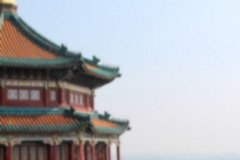

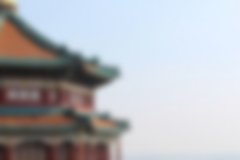

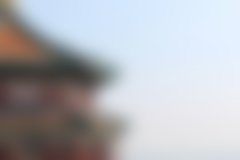

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageFilter

ausschnitt = foto.crop((200, 50, 440, 210))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageFilter

ausschnitt = foto.crop((200, 50, 440, 210))
for radius in [1, 3, 8]:
    display(ausschnitt.filter(ImageFilter.GaussianBlur(radius)))
```

</details>

#### Aufgabe 4.2

Zeige den Ausschnitt mit den Filtern `SHARPEN` und `EMBOSS` an.

**Erwartete Ausgabe:**



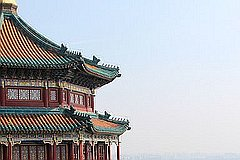

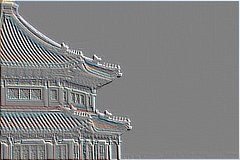

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageFilter

ausschnitt = foto.crop((200, 50, 440, 210))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageFilter

ausschnitt = foto.crop((200, 50, 440, 210))
display(ausschnitt.filter(ImageFilter.SHARPEN))
display(ausschnitt.filter(ImageFilter.EMBOSS))
```

</details>

#### Aufgabe 4.3

Kanten in Graustufen: Wandle den Ausschnitt in Graustufen um, wende `FIND_EDGES` an und mache das Ergebnis mit `ImageOps.invert()` zu dunklen Kanten auf Weiß.

**Erwartete Ausgabe:**



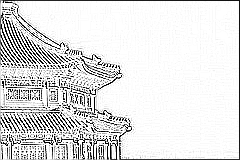

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageFilter

ausschnitt = foto.crop((200, 50, 440, 210))
from PIL import ImageOps
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageFilter

ausschnitt = foto.crop((200, 50, 440, 210))
from PIL import ImageOps
kanten = ausschnitt.convert('L').filter(ImageFilter.FIND_EDGES)
ImageOps.invert(kanten)
```

</details>

#### Aufgabe 4.4

Störpixel entfernen: In der Zelle wird der Ausschnitt mit 2000 zufälligen weißen Pixeln „beschädigt“. Zeige ihn an und dann repariert mit `MedianFilter(3)`.

**Erwartete Ausgabe:**



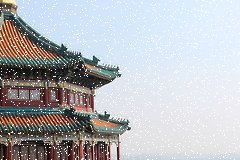

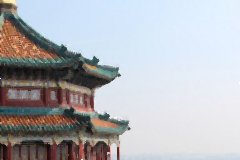

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageFilter

ausschnitt = foto.crop((200, 50, 440, 210))
import random

random.seed(4)
kaputt = ausschnitt.copy()
for i in range(2000):
    kaputt.putpixel((random.randint(0, 239), random.randint(0, 159)), (255, 255, 255))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageFilter

ausschnitt = foto.crop((200, 50, 440, 210))
import random

random.seed(4)
kaputt = ausschnitt.copy()
for i in range(2000):
    kaputt.putpixel((random.randint(0, 239), random.randint(0, 159)), (255, 255, 255))
display(kaputt)
kaputt.filter(ImageFilter.MedianFilter(3))
```

</details>

#### Aufgabe 4.5

Ein **Fokus-Effekt**: Zeichne die ganze Pagode stark weich (`GaussianBlur(6)`) und füge dann den scharfen Ausschnitt (200 | 50) bis (440 | 210) wieder an derselben Stelle ein
(`unscharf.paste(ausschnitt, (200, 50))`, siehe Abschnitt 6).

**Erwartete Ausgabe:**



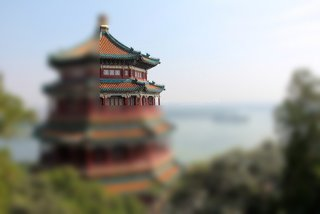

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageFilter

ausschnitt = foto.crop((200, 50, 440, 210))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageFilter

ausschnitt = foto.crop((200, 50, 440, 210))
unscharf = foto.filter(ImageFilter.GaussianBlur(6))
unscharf.paste(ausschnitt, (200, 50))
unscharf
```

</details>

#### Aufgabe 4.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from PIL import Image, ImageFilter

bild = Image.new('L', (5, 5), 100)
print(bild.filter(ImageFilter.BLUR).getpixel((2, 2)))
print(bild.filter(ImageFilter.FIND_EDGES).getpixel((2, 2)))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
100
0
```

Das Bild ist überall gleich hell (100).
- Weichzeichnen mittelt Nachbarn mit demselben Wert, es bleibt `100`.
- Kanten gibt es nur, wo sich die Helligkeit ändert, also nirgends: `0`.

</details>

## 5. Helligkeit, Kontrast und Sättigung

#### `ImageEnhance`

`ImageEnhance.Brightness(foto).enhance(1.5)` macht ein Bild 1.5-mal so hell. Der Faktor 1 lässt es unverändert, kleinere Faktoren schwächen ab.
Genauso funktionieren `Contrast` (Kontrast), `Color` (Sättigung; 0 ergibt Graustufen) und `Sharpness` (Schärfe).

`ImageOps.autocontrast(foto)` streckt die Helligkeiten so, dass das dunkelste Pixel schwarz und das hellste weiß wird.

In [ ]:
from PIL import Image

foto = Image.open('bluete.png')
from PIL import ImageEnhance

klein = foto.resize((213, 142))
display(ImageEnhance.Brightness(klein).enhance(1.5))
display(ImageEnhance.Contrast(klein).enhance(2.0))
ImageEnhance.Color(klein).enhance(0.3)

#### Aufgabe 5.1

Zeige die Blüte mit den Helligkeitsfaktoren 0.5 und 1.5 an. Gib jeweils die Farbe des Pixels (100 | 70) aus.

**Erwartete Ausgabe:**

```
0.5 (102, 50, 30)
1.5 (255, 150, 91)
```

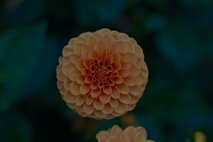

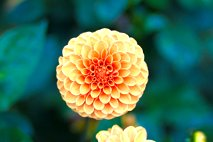

In [ ]:
from PIL import Image

foto = Image.open('bluete.png')

klein = foto.resize((213, 142))
from PIL import ImageEnhance
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('bluete.png')

klein = foto.resize((213, 142))
from PIL import ImageEnhance
for faktor in [0.5, 1.5]:
    hell = ImageEnhance.Brightness(klein).enhance(faktor)
    print(faktor, hell.getpixel((100, 70)))
    display(hell)
```

</details>

#### Aufgabe 5.2

Zeige die Blüte mit den Sättigungsfaktoren 0 (grau), 0.5 und 2 (knallig) an.

**Erwartete Ausgabe:**



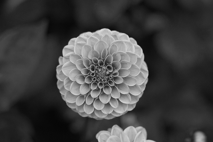

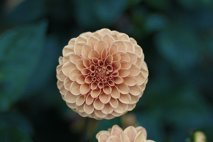

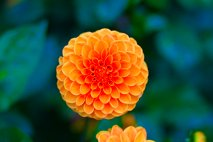

In [ ]:
from PIL import Image

foto = Image.open('bluete.png')

klein = foto.resize((213, 142))
from PIL import ImageEnhance
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('bluete.png')

klein = foto.resize((213, 142))
from PIL import ImageEnhance
for faktor in [0, 0.5, 2]:
    display(ImageEnhance.Color(klein).enhance(faktor))
```

</details>

#### Aufgabe 5.3

Ein flaues Foto verbessern: In der Zelle wird die Pagode mit `Contrast(...).enhance(0.4)` künstlich flau gemacht. Zeige sie an, dann mit `ImageOps.autocontrast()` verbessert.
Gib vorher und nachher das dunkelste und hellste Pixel des Graustufenbilds aus (`convert('L').getextrema()`).

**Erwartete Ausgabe:**

```
(87, 188) (0, 254)
```

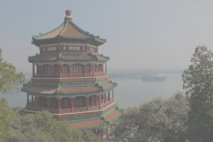

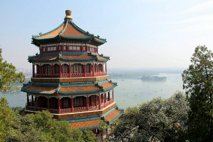

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageEnhance, ImageOps

flau = ImageEnhance.Contrast(foto.resize((213, 142))).enhance(0.4)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
from PIL import ImageEnhance, ImageOps

flau = ImageEnhance.Contrast(foto.resize((213, 142))).enhance(0.4)
besser = ImageOps.autocontrast(flau)
print(flau.convert('L').getextrema(), besser.convert('L').getextrema())
display(flau)
besser
```

</details>

#### Aufgabe 5.4

Ein **Retro-Filter**: Verringere die Sättigung der Blüte auf 0.5, erhöhe den Kontrast auf 1.3 und gib ihr einen Rahmen aus 12 Pixeln in `'beige'`.

**Erwartete Ausgabe:**



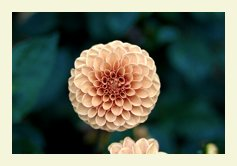

In [ ]:
from PIL import Image

foto = Image.open('bluete.png')

klein = foto.resize((213, 142))
from PIL import ImageEnhance
from PIL import ImageOps
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('bluete.png')

klein = foto.resize((213, 142))
from PIL import ImageEnhance
from PIL import ImageOps
retro = ImageEnhance.Color(klein).enhance(0.5)
retro = ImageEnhance.Contrast(retro).enhance(1.3)
ImageOps.expand(retro, border=12, fill='beige')
```

</details>

## 6. Einfügen, Transparenz und Collagen

#### `paste()`, `Image.blend()` und `alpha_composite()`

- `hintergrund.paste(bild, (x, y))` setzt `bild` mit der oberen linken Ecke bei `(x, y)` in `hintergrund` ein (verändert `hintergrund`).
- `Image.blend(a, b, 0.3)` mischt zwei gleich große Bilder: 70 % von `a` und 30 % von `b`.
- Für Transparenz braucht man RGBA-Bilder: `Image.alpha_composite(unten, oben)` legt `oben` über `unten`, durchsichtige Pixel lassen `unten` durchscheinen.
  `bild.putalpha(128)` macht ein ganzes Bild halb durchsichtig.

In [ ]:
from PIL import Image

pagode = Image.open('pagode.png').resize((213, 142))
bluete = Image.open('bluete.png').resize((213, 142))
leinwand = Image.new('RGB', (446, 162), 'white')
leinwand.paste(pagode, (10, 10))
leinwand.paste(bluete, (223, 10))
display(leinwand)
Image.blend(pagode, bluete, 0.5)

#### Aufgabe 6.1

Lege eine **Collage** aus vier Bildern an: eine weiße Leinwand 446 × 304, darauf im 2 × 2-Raster mit 10 Pixeln Abstand die Pagode, die Blüte, die Pagode in Graustufen
(`convert('L').convert('RGB')`) und die gespiegelte Blüte.

**Erwartete Ausgabe:**



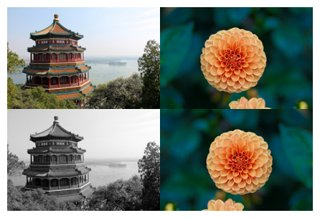

In [ ]:
from PIL import Image

pagode = Image.open('pagode.png').resize((213, 142))
bluete = Image.open('bluete.png').resize((213, 142))
from PIL import ImageOps
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

pagode = Image.open('pagode.png').resize((213, 142))
bluete = Image.open('bluete.png').resize((213, 142))
from PIL import ImageOps
leinwand = Image.new('RGB', (446, 304), 'white')
bilder = [pagode, bluete, pagode.convert('L').convert('RGB'), ImageOps.mirror(bluete)]
for i, bild in enumerate(bilder):
    leinwand.paste(bild, (10 + i % 2 * 213, 10 + i // 2 * 142))
leinwand
```

</details>

#### Aufgabe 6.2

Zeige Überblendungen von Pagode und Blüte mit den Anteilen 0.2 und 0.8 an.

**Erwartete Ausgabe:**



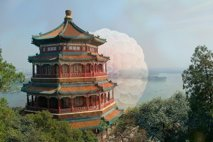

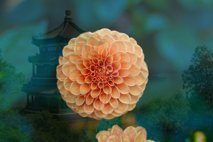

In [ ]:
from PIL import Image

pagode = Image.open('pagode.png').resize((213, 142))
bluete = Image.open('bluete.png').resize((213, 142))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

pagode = Image.open('pagode.png').resize((213, 142))
bluete = Image.open('bluete.png').resize((213, 142))
for anteil in [0.2, 0.8]:
    display(Image.blend(pagode, bluete, anteil))
```

</details>

#### Aufgabe 6.3

Ein **Wasserzeichen**: Erzeuge eine durchsichtige Ebene (`Image.new('RGBA', pagode.size, (0, 0, 0, 0))`), schreibe darauf „© Mia“ in Weiß mit Alpha 160 in Größe 28 unten rechts
(Mittelpunkt (160 | 120)) und lege sie mit `alpha_composite()` über die Pagode (vorher `convert('RGBA')`).

**Erwartete Ausgabe:**



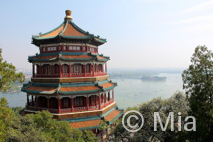

In [ ]:
from PIL import Image

pagode = Image.open('pagode.png').resize((213, 142))
bluete = Image.open('bluete.png').resize((213, 142))
from PIL import ImageDraw, ImageFont
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

pagode = Image.open('pagode.png').resize((213, 142))
bluete = Image.open('bluete.png').resize((213, 142))
from PIL import ImageDraw, ImageFont
ebene = Image.new('RGBA', pagode.size, (0, 0, 0, 0))
zeichner = ImageDraw.Draw(ebene)
zeichner.text((160, 120), '© Mia', fill=(255, 255, 255, 160), font=ImageFont.load_default(size=28), anchor='mm')
Image.alpha_composite(pagode.convert('RGBA'), ebene)
```

</details>

#### Aufgabe 6.4

Ein **Bild im Bild**: Verkleinere die Blüte auf 90 × 60, gib ihr einen weißen Rahmen von 3 Pixeln und setze sie in die obere rechte Ecke der Pagode (10 Pixel Abstand vom Rand).

**Erwartete Ausgabe:**



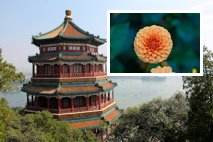

In [ ]:
from PIL import Image

pagode = Image.open('pagode.png').resize((213, 142))
bluete = Image.open('bluete.png').resize((213, 142))
from PIL import ImageOps
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

pagode = Image.open('pagode.png').resize((213, 142))
bluete = Image.open('bluete.png').resize((213, 142))
from PIL import ImageOps
klein = ImageOps.expand(bluete.resize((90, 60)), border=3, fill='white')
ergebnis = pagode.copy()
ergebnis.paste(klein, (pagode.width - klein.width - 10, 10))
ergebnis
```

</details>

#### Aufgabe 6.5

Eine **runde** Blüte: Erzeuge eine Maske `Image.new('L', (142, 142), 0)`, zeichne darauf einen weißen Kreis (Mittelpunkt (71 | 71), Radius 70), schneide aus der Blüte
ein 142 × 142-Quadrat aus der Mitte und füge es mit `leinwand.paste(quadrat, (10, 10), maske)` auf eine hellgraue 162 × 162-Leinwand ein. Nur wo die Maske weiß ist,
wird eingefügt.

**Erwartete Ausgabe:**



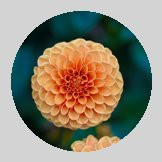

In [ ]:
from PIL import Image

pagode = Image.open('pagode.png').resize((213, 142))
bluete = Image.open('bluete.png').resize((213, 142))
from PIL import ImageDraw
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

pagode = Image.open('pagode.png').resize((213, 142))
bluete = Image.open('bluete.png').resize((213, 142))
from PIL import ImageDraw
maske = Image.new('L', (142, 142), 0)
ImageDraw.Draw(maske).circle((71, 71), 70, fill=255)
quadrat = bluete.crop((35, 0, 177, 142))
leinwand = Image.new('RGB', (162, 162), 'lightgray')
leinwand.paste(quadrat, (10, 10), maske)
leinwand
```

</details>

#### Aufgabe 6.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from PIL import Image

a = Image.new('RGB', (1, 1), (0, 0, 0))
b = Image.new('RGB', (1, 1), (200, 100, 50))
print(Image.blend(a, b, 0.5).getpixel((0, 0)))
print(Image.blend(a, b, 1.0).getpixel((0, 0)))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
(100, 50, 25)
(200, 100, 50)
```

`blend` berechnet `a · (1 - anteil) + b · anteil`:
- Mit 0.5 die Hälfte von `b`: `(100, 50, 25)`.
- Mit 1.0 genau `b`: `(200, 100, 50)`.

</details>

## 7. Animierte GIFs

#### Mehrere Bilder in einer Datei

Ein animiertes GIF ist eine Folge von Bildern (**Frames**). Man erzeugt die Frames als Liste von Bildern und speichert sie mit
`frames[0].save('name.gif', save_all=True, append_images=frames[1:], duration=100, loop=0)`: `duration` ist die Anzeigedauer jedes Bilds in Millisekunden,
`loop=0` wiederholt die Animation endlos.

Pillow zeigt im Notebook nur das erste Bild an. Die Animation zeigt `IPython.display.Image(filename='name.gif')` an.

In [ ]:
from PIL import Image, ImageDraw
from IPython.display import Image as AnimiertesBild

frames = []
for i in range(20):
    bild = Image.new('RGB', (200, 100), 'white')
    zeichner = ImageDraw.Draw(bild)
    x = 10 + i * 9
    zeichner.circle((x, 50), 15, fill='red')
    frames.append(bild)
frames[0].save('ball.gif', save_all=True, append_images=frames[1:], duration=80, loop=0)
print(Image.open('ball.gif').n_frames)
AnimiertesBild(filename='ball.gif')

#### Aufgabe 7.1

Erzeuge ein GIF aus 12 Frames, in denen ein blaues Quadrat (40 × 40) auf einem 200 × 200-Bild im Kreis läuft (Mittelpunkt des Quadrats im Abstand 60 um die Bildmitte,
alle 30°). Speichere es als `kreis.gif` und gib die Anzahl der Frames aus.

In [ ]:
from PIL import Image, ImageDraw
from IPython.display import Image as AnimiertesBild
import math
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw
from IPython.display import Image as AnimiertesBild
import math
frames = []
for i in range(12):
    bild = Image.new('RGB', (200, 200), 'white')
    w = math.radians(30 * i)
    x = 100 + 60 * math.cos(w)
    y = 100 + 60 * math.sin(w)
    ImageDraw.Draw(bild).rectangle((x - 20, y - 20, x + 20, y + 20), fill='blue')
    frames.append(bild)
frames[0].save('kreis.gif', save_all=True, append_images=frames[1:], duration=100, loop=0)
print(Image.open('kreis.gif').n_frames)
AnimiertesBild(filename='kreis.gif')
```

</details>

#### Aufgabe 7.2

Ein Überblend-GIF: 11 Frames, in denen die verkleinerte Pagode in die Blüte übergeht (`Image.blend` mit den Anteilen 0, 0.1, ..., 1.0). Speichere es als `ueberblenden.gif`.

In [ ]:
from PIL import Image

pagode = Image.open('pagode.png').resize((213, 142))
bluete = Image.open('bluete.png').resize((213, 142))
from IPython.display import Image as AnimiertesBild
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

pagode = Image.open('pagode.png').resize((213, 142))
bluete = Image.open('bluete.png').resize((213, 142))
from IPython.display import Image as AnimiertesBild
frames = [Image.blend(pagode, bluete, i / 10) for i in range(11)]
frames[0].save('ueberblenden.gif', save_all=True, append_images=frames[1:], duration=150, loop=0)
AnimiertesBild(filename='ueberblenden.gif')
```

</details>

#### Aufgabe 7.3

Ein Zähler: 10 Frames mit den Zahlen 9 bis 0 groß in der Mitte (Größe 80) eines 150 × 150-Bilds, jedes Frame 500 ms lang.

In [ ]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import Image as AnimiertesBild
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw, ImageFont
from IPython.display import Image as AnimiertesBild
frames = []
for zahl in range(9, -1, -1):
    bild = Image.new('RGB', (150, 150), 'black')
    ImageDraw.Draw(bild).text((75, 75), str(zahl), fill='white', font=ImageFont.load_default(size=80), anchor='mm')
    frames.append(bild)
frames[0].save('zaehler.gif', save_all=True, append_images=frames[1:], duration=500, loop=0)
AnimiertesBild(filename='zaehler.gif')
```

</details>

## 8. Gemischte Übungen

#### Aufgabe 8.1

Erzeuge eine **Postkarte**: Die Pagode, auf 300 × 200 zugeschnitten (`ImageOps.fit`), etwas heller (1.2) und kräftiger (Sättigung 1.3), mit dem Text „Grüße aus China“
(Größe 24, weiß, Mitte bei (150 | 175)) und einem weißen Rahmen von 10 Pixeln. Für das „ü“ und „ß“ brauchst du die Schrift DejaVu Sans aus matplotlib
(siehe *Pillow: Zeichnen*, Abschnitt Text).

**Erwartete Ausgabe:**



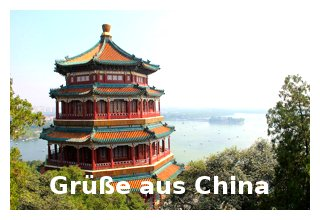

In [ ]:
from PIL import Image, ImageDraw, ImageEnhance, ImageFont, ImageOps
import matplotlib
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw, ImageEnhance, ImageFont, ImageOps
import matplotlib
karte = ImageOps.fit(Image.open('pagode.png'), (300, 200))
karte = ImageEnhance.Brightness(karte).enhance(1.2)
karte = ImageEnhance.Color(karte).enhance(1.3)
schrift = ImageFont.truetype(matplotlib.get_data_path() + '/fonts/ttf/DejaVuSans-Bold.ttf', 24)
ImageDraw.Draw(karte).text((150, 175), 'Grüße aus China', fill='white', font=schrift, anchor='mm')
ImageOps.expand(karte, border=10, fill='white')
```

</details>

#### Aufgabe 8.2

Ein Kontaktabzug: Erzeuge aus der Blüte 6 Varianten (Original, Graustufen, Negativ, weichgezeichnet, Kanten, gespiegelt), jede auf 120 × 80 verkleinert, und setze sie
in einem 3 × 2-Raster (5 Pixel Abstand) auf eine schwarze Leinwand.

**Erwartete Ausgabe:**



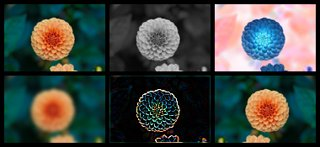

In [ ]:
from PIL import Image, ImageFilter, ImageOps

klein = Image.open('bluete.png').resize((120, 80))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageFilter, ImageOps

klein = Image.open('bluete.png').resize((120, 80))
varianten = [klein, ImageOps.grayscale(klein).convert('RGB'), ImageOps.invert(klein),
             klein.filter(ImageFilter.GaussianBlur(2)), klein.filter(ImageFilter.FIND_EDGES), ImageOps.mirror(klein)]
leinwand = Image.new('RGB', (3 * 125 + 5, 2 * 85 + 5), 'black')
for i, bild in enumerate(varianten):
    leinwand.paste(bild, (5 + i % 3 * 125, 5 + i // 3 * 85))
leinwand
```

</details>

#### Aufgabe 8.3

Viele Bilder auf einmal bearbeiten: Erzeuge für beide Fotos ein Vorschaubild (passend in 160 × 160) in Graustufen mit Rahmen und speichere es als `vorschau_pagode.png`
bzw. `vorschau_bluete.png`. Öffne die gespeicherten Dateien und gib Name und Größe aus.

**Erwartete Ausgabe:**

```
pagode (168, 115)
bluete (168, 115)
```

In [ ]:
from PIL import Image, ImageOps
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageOps
for name in ['pagode', 'bluete']:
    bild = Image.open(f'{name}.png').convert('L')
    bild.thumbnail((160, 160))
    ImageOps.expand(bild, border=4, fill='white').save(f'vorschau_{name}.png')
for name in ['pagode', 'bluete']:
    print(name, Image.open(f'vorschau_{name}.png').size)
```

</details>

#### Aufgabe 8.4

Bearbeite ein eigenes Foto (hochladen, siehe oben) mit mindestens drei Werkzeugen aus diesem Notebook und speichere das Ergebnis.

In [ ]:
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageEnhance, ImageFilter, ImageOps

foto = Image.open('pagode.png')
foto = ImageOps.fit(foto, (300, 300))
foto = ImageEnhance.Contrast(foto).enhance(1.4)
foto = foto.filter(ImageFilter.SHARPEN)
foto.save('mein_bild.png')
foto
```

</details>